In [1]:
import pandas as pd
df = pd.read_csv("wa_fn-usec_-telco-customer-churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()
print(df.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("blank TotalCharges:",df["TotalCharges"].isnull().sum())
df[df["TotalCharges"].isnull()][["customerID","tenure","MonthlyCharges","TotalCharges"]]

blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [4]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df["TotalCharges"].isnull().sum())

0


In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:",df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [6]:
df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)
print(df["Churn_flag"].value_counts())
print("Churn rate:", round(df["Churn_flag"].mean() * 100,2),"%")

Churn_flag
0    5174
1    1869
Name: count, dtype: int64
Churn rate: 26.54 %


In [7]:
for col in ["Contract","InternetService","PaymentMethod"]:
    print(df[col].value_counts(),"\n")

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64 

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64 

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64 



In [8]:
df.to_csv("telco_clean.csv", index=False)

In [9]:
for col in ["Contract","InternetService","PaymentMethod"]:
    print((df.groupby(col)["Churn_flag"].mean() * 100).round(2).sort_values(ascending=False),"\n")

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn_flag, dtype: float64 

InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn_flag, dtype: float64 

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn_flag, dtype: float64 



In [10]:
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48,72],
labels=["0-12","13-24","25-48","49-72"])
print((df.groupby("tenure_group", observed=True)["Churn_flag"].mean()*100).round(2))

tenure_group
0-12     47.44
13-24    28.71
25-48    20.39
49-72     9.51
Name: Churn_flag, dtype: float64


In [11]:
print(df.groupby("Churn")[["tenure","MonthlyCharges","TotalCharges"]].mean().round(2))

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No      37.57           61.27       2549.91
Yes     17.98           74.44       1531.80


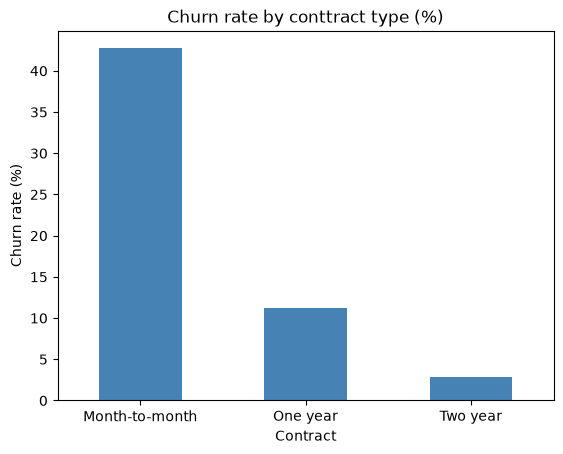

In [12]:
import matplotlib.pyplot as plt
rate = df.groupby("Contract")["Churn_flag"].mean() * 100
rate.plot(kind="bar",color="steelblue")
plt.title("Churn rate by conttract type (%)")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.show()

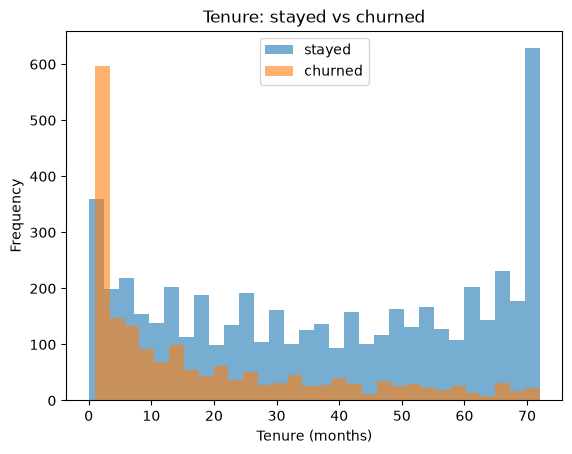

In [13]:
df[df["Churn"] == "No"]["tenure"].plot(kind="hist",bins=30,alpha=0.6,label="stayed")
df[df["Churn"] == "Yes"]["tenure"].plot(kind="hist",bins=30,alpha=0.6,label="churned")
plt.legend()
plt.title("Tenure: stayed vs churned")
plt.xlabel("Tenure (months)")
plt.show()

In [14]:
from scipy import stats
import numpy as np

def chi_test(col):
    table = pd.crosstab(df[col], df["Churn_flag"])
    chi2, p, dof, exp = stats.chi2_contingency(table)
    n = table.values.sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return round(chi2, 1), p, round(v, 3)

for col in ["Contract", "InternetService", "PaymentMethod", "SeniorCitizen", "gender"]:
    chi2, p, v = chi_test(col)
    print(f"{col}: chi2={chi2}, p={p:.4g}, Cramer's V={v}")

Contract: chi2=1184.6, p=5.863e-258, Cramer's V=0.41
InternetService: chi2=732.3, p=9.572e-160, Cramer's V=0.322
PaymentMethod: chi2=648.1, p=3.682e-140, Cramer's V=0.303
SeniorCitizen: chi2=159.4, p=1.51e-36, Cramer's V=0.15
gender: chi2=0.5, p=0.4866, Cramer's V=0.008


In [15]:
for col in ["tenure", "MonthlyCharges"]:
    a = df[df["Churn_flag"] == 1][col]
    b = df[df["Churn_flag"] == 0][col]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var())/2)
    print(f"{col}: churned={a.mean():.2f}, stayed={b.mean():.2f}, t={t:.2f}, p={p:.4g}, cohen's d={d:.2f}")


tenure: churned=17.98, stayed=37.57, t=-34.82, p=1.195e-232, cohen's d=-0.89
MonthlyCharges: churned=74.44, stayed=61.27, t=18.41, p=8.592e-73, cohen's d=0.47


In [16]:
from statsmodels.stats.proportion import confint_proportions_2indep

m = df[df["Contract"] == "Month-to-month"]["Churn_flag"]
t2 = df[df["Contract"] == "Two year"]["Churn_flag"]
low, high = confint_proportions_2indep(m.sum(), len(m), t2.sum(), len(t2), method="wald")
print("Month-to-month minus two-year churn gap:", round(low*100,2),"to", round(high*100, 2), "points")

Month-to-month minus two-year churn gap: 38.13 to 41.62 points


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report,roc_auc_score,confusion_matrix

X = df.drop(columns=["customerID", "Churn", "Churn_flag", "tenure_group"], errors="ignore")
y = df["Churn_flag"]
X = pd.get_dummies(X, drop_first=True).astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

num = ["tenure","MonthlyCharges","TotalCharges"]
scaler = StandardScaler()
X_train[num] = scaler.fit_transform(X_train[num])
X_test[num] = scaler.transform(X_test[num])
print(X_train.shape, X_test.shape)


(5634, 30) (1409, 30)


In [18]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
pred = lr.predict(X_test)
proba = lr.predict_proba(X_test)[:, 1]

print(classification_report(y_test,pred))
print("roc_auc:", round(roc_auc_score(y_test,proba),3))
print(confusion_matrix(y_test, pred))

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

roc_auc: 0.842
[[927 108]
 [165 209]]


In [19]:
print([c for c in X.columns if "hurn" in c])

[]


In [20]:
print(X.shape, X_train.shape, X_test.shape)

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
pred = lr.predict(X_test)
proba = lr.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print(confusion_matrix(y_test, pred))

(7043, 30) (5634, 30) (1409, 30)
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

ROC-AUC: 0.842
[[927 108]
 [165 209]]


In [21]:
lr2 = LogisticRegression(max_iter=1000, class_weight="balanced")
lr2.fit(X_train, y_train)
pred2 = lr2.predict(X_test)
print(classification_report(y_test, pred2))
print("ROC-AUC:", round(roc_auc_score(y_test, lr2.predict_proba(X_test)[:, 1]), 3))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.842


In [22]:
print(classification_report(y_test, lr.predict(X_test)))
print("ROC-AUC:", round(roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1]), 3))

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

ROC-AUC: 0.842


In [23]:
coefs = pd.Series(lr2.coef_[0], index=X.columns)
odds = np.exp(coefs).sort_values(ascending=False)
print(odds.head(8).round(2))
print(odds.tail(8).round(2))

InternetService_Fiber optic       3.40
TotalCharges                      1.63
StreamingMovies_Yes               1.52
PaymentMethod_Electronic check    1.50
StreamingTV_Yes                   1.48
PaperlessBilling_Yes              1.40
MultipleLines_Yes                 1.38
SeniorCitizen                     1.17
dtype: float64
Dependents_Yes        0.79
TechSupport_Yes       0.76
OnlineSecurity_Yes    0.72
PhoneService_Yes      0.71
MonthlyCharges        0.58
Contract_One year     0.49
tenure                0.31
Contract_Two year     0.24
dtype: float64


In [24]:
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].corr().round(2))

                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00


In [25]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                            class_weight="balanced", random_state=42, n_jobs=-1)

rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
proba_rf = rf.predict_proba(X_test)[:,1]

print(classification_report(y_test, pred_rf))
print("roc-auc:", round(roc_auc_score(y_test, proba_rf),3))
print(confusion_matrix(y_test, pred_rf))

              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.52      0.80      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409

roc-auc: 0.845
[[756 279]
 [ 74 300]]


tenure                             0.178
Contract_Two year                  0.138
TotalCharges                       0.123
InternetService_Fiber optic        0.086
MonthlyCharges                     0.071
PaymentMethod_Electronic check     0.065
Contract_One year                  0.046
OnlineSecurity_Yes                 0.042
TechSupport_No internet service    0.025
TechSupport_Yes                    0.023
dtype: float64


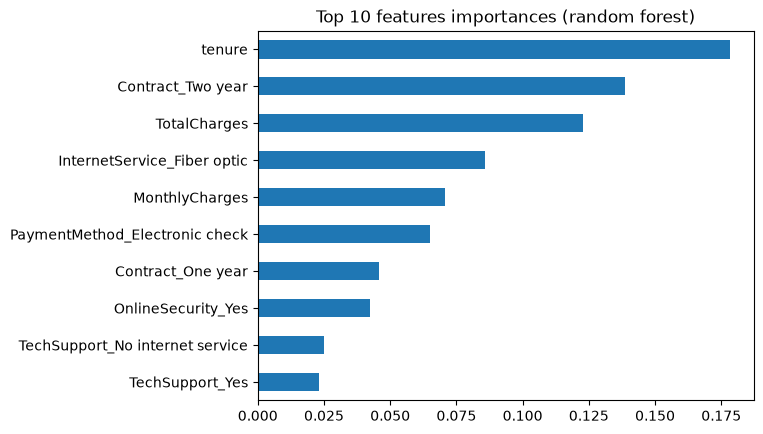

In [26]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(10).round(3))
imp.head(10).sort_values().plot(kind="barh", title="Top 10 features importances (random forest)")
plt.show()

In [27]:
from sklearn.metrics import recall_score,precision_score

rows = []
for name, p, pr in [("Logistic (balanced)", lr2.predict(X_test),lr2.predict_proba(X_test)[:, 1]),
                    ("Random forest (balanced)", pred_rf, proba_rf)]:
    rows.append([name, round(precision_score(y_test, p),3),
                 round(recall_score(y_test, p), 3), round(roc_auc_score(y_test,pr),3)])
    pd.DataFrame(rows, columns=["Model","Precision (churn)", "Recall (churn)", "roc_auc"])

In [28]:
comp = pd.DataFrame(rows, columns=["Model", "precision (churn)", "Reacall (churn)", "roc-auc"])
print(comp.to_string(index=False))

                   Model  precision (churn)  Reacall (churn)  roc-auc
     Logistic (balanced)              0.504            0.783    0.842
Random forest (balanced)              0.518            0.802    0.845


In [29]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(5, shuffle=True, random_state=42)
lr_cv = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))

for name, model in [("Logistic", lr_cv), ("Random forest", rf)]:
    s = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
    print(name, "ROC-AUC:", round(s.mean(), 3), "+/-", round(s.std(), 3))

Logistic ROC-AUC: 0.845 +/- 0.013
Random forest ROC-AUC: 0.847 +/- 0.012


In [35]:
# 1. How many churners do the riskiest customers hold?
test = pd.DataFrame({"actual": y_test.values,
                     "score": lr2.predict_proba(X_test)[:, 1]})
test = test.sort_values("score", ascending=False).reset_index(drop=True)

for pct in [0.1,0.2,0.3]:
    n = int(len(test) * pct)
    caught = test.loc[:n-1, "actual"].sum() / test["actual"].sum()
    print(f"Top {int(pct*100)}% riskiest customers hold {caught*100:.1f}% of all churnes")

# 2. Simple business case (the three numbers below are ASSUMPTIONS)
    offer_cost = 20
    success_rate = 0.30
    months_saved = 12

    avg_monthly = df.loc[df["Churn_flag"] == 1, "MonthlyCharges"].mean()
    n = int(len(test)*0.2)
    reached = test.loc[:n-1, "actual"].sum()
    cost = n * offer_cost
    saved = reached * success_rate * avg_monthly * months_saved

    print("\nCustomers contacted:", n)
    print("churners reached:", int(reached))
    print("champaign cost: $", round(cost))
    print("revenue saved: $", round(saved))
    print("net benefit: $", round(saved - cost))

    # 3. Highest-risk segment
    seg = df[(df["Contract"] == "Month-to-month") &
             (df["InternetService"] == "Fiber optic") &
             (df["PaymentMethod"] == "Electronic check")]
    print("\nsegment customers:", len(seg), "churn rate:", round(seg["Churn_flag"].mean()*100, 1), "%")

Top 10% riskiest customers hold 28.3% of all churnes

Customers contacted: 281
churners reached: 186
champaign cost: $ 5620
revenue saved: $ 49846
net benefit: $ 44226

segment customers: 1307 churn rate: 60.4 %
Top 20% riskiest customers hold 49.7% of all churnes

Customers contacted: 281
churners reached: 186
champaign cost: $ 5620
revenue saved: $ 49846
net benefit: $ 44226

segment customers: 1307 churn rate: 60.4 %
Top 30% riskiest customers hold 65.0% of all churnes

Customers contacted: 281
churners reached: 186
champaign cost: $ 5620
revenue saved: $ 49846
net benefit: $ 44226

segment customers: 1307 churn rate: 60.4 %


In [38]:
from sklearn.model_selection import cross_val_predict

scores = cross_val_predict(lr_cv, X, y, cv=cv, method="predict_proba")[:, 1]

out = df.copy()
out["risk_score"] = scores
rank = out["risk_score"].rank(pct=True, ascending=False)
out["risk_band"] = np.where(rank <= 0.2, "High", np.where(rank <= 0.5, "Medium", "Low"))

cols = ["customerID", "Contract", "InternetService", "PaymentMethod", "tenure",
        "tenure_group", "MonthlyCharges", "TotalCharges", "Churn", "Churn_flag",
        "risk_score", "risk_band"]
out[cols].to_csv("churn_dashboard_data.csv", index=False)
print(out["risk_band"].value_counts())
print(out.groupby("risk_band")["Churn_flag"].mean().round(3))

risk_band
Low       3522
Medium    2113
High      1408
Name: count, dtype: int64
risk_band
High      0.677
Low       0.067
Medium    0.322
Name: Churn_flag, dtype: float64
